# Regime Structure 04 — does 0DTE implied vol underreact to yesterday's realised vol?

Pre-registration: `discussions/Regime_Structure/009_claude_rs04_rs05_preregistration.md` §2. Code: `big_move_followups.py`.

- **Predictor** $x=\log(\text{RV}_{\text{yesterday}}/\hat\sigma_{7})$ — RS 03's one confirmed feature, known at 08:00 (Binance 1m).
- **Entry:** ATM 0DTE straddle of the primary family at 12:00 UTC (20 h to expiry), VRP 02 code.
- **Outcome:** $y=\log(\text{realised move}/\text{implied move})$. **Decision:** OLS slope $\beta$ of $y$ on $x$, 95% session bootstrap — UNDERREACTION if CI > 0, OVERREACTION if CI < 0, else NO_EVIDENCE.
- Reported: slopes of realised and implied move (each over $\hat\sigma$) on $x$; straddle $R_{\text{net}}$ by predictor tercile (cutoffs from the RS 03 development window).

Environment: `RS04_ASSETS`, `RS04_OFFLINE=1` (cached delivery prices), `RS04_SYNTHETIC=1`.

In [1]:
from pathlib import Path
import json, os, sys, tempfile, time, warnings, importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from dataclasses import replace

warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.max_columns', 40); pd.set_option('display.width', 250)
load_dotenv()
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT / 'src'))
from data_engineering.modeling import big_move_days as bm, vrp_long_straddle as ls, big_move_followups as bf
bm, ls, bf = importlib.reload(bm), importlib.reload(ls), importlib.reload(bf)
SYNTHETIC = os.getenv('RS04_SYNTHETIC', '').strip() == '1'
ASSETS = [a.strip().upper() for a in os.getenv('RS04_ASSETS', ','.join(bm.ASSETS)).split(',') if a.strip()]
P = bf.Params()
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='rs04_')); DATA_ROOT = BIN_DIR = None
else:
    DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
    BIN_DIR = Path(os.getenv('BINANCE_UM_DIR') or DATA_ROOT.parent / 'Binance').expanduser().resolve()
    OUT = PROJECT_ROOT / 'notebooks' / 'Regime_Structure' / '04'
OUT.mkdir(parents=True, exist_ok=True)
print('RS 04 |', bf.VERSION, '|', bm.VERSION, '| synthetic' if SYNTHETIC else '', '| out', OUT)

def load_binance(a, i):
    if SYNTHETIC:
        return bm.synthetic_klines(n_days=760, seed=70 + i, start='2024-10-01', planted=False)
    path = BIN_DIR / f'{a}USDT_um_1m.parquet'
    if not path.exists():
        print(f'{a}: no Binance file -> skipped'); return None
    return pd.read_parquet(path, columns=['open_time', 'close', 'volume', 'taker_buy_volume', 'trades'])

RS 04 | big_move_followups v1.0 | big_move_days v1.0  | out D:\Projects\deribit_market_data\notebooks\Regime_Structure\04


## 1. Predictor from Binance

In [2]:
TABLES = {}
for i, a in enumerate(ASSETS):
    df = load_binance(a, i)
    if df is None:
        continue
    TABLES[a] = bm.run_asset(df, a, bm.Params())['table']
    del df
PRED = bf.predictor_table(TABLES)
CUT = bf.tercile_cutoffs(PRED)
print('tercile cutoffs of x (RS 03 dev window):', np.round(CUT, 4))

tercile cutoffs of x (RS 03 dev window): [-0.1859  0.05  ]


## 2. 12:00 UTC straddles on the collector quotes and settlement

In [3]:
if SYNTHETIC:
    parts = [ls._fake_chain(np.random.default_rng(80 + i), n_sessions=30, vol=0.6, iv=0.6, half_spread=0.03, under=a)
             for i, a in enumerate(TABLES)]
    chain = pd.concat([c for c, _ in parts], ignore_index=True); approx = pd.concat([s for _, s in parts], ignore_index=True)
    # synthetic chains are dated 2026-04-01..: shift the predictor sessions onto them
    sess = sorted(chain['state_time'].dt.normalize().dt.strftime('%Y-%m-%d').unique())
else:
    import duckdb
    con = duckdb.connect(str(DATA_ROOT / 'database' / 'research.duckdb'), read_only=True)
    try:
        have = set(con.execute('DESCRIBE normalized_option_chain').df()['column_name'])
        cols = [c for c in ls.CHAIN_COLUMNS if c != 'settlement_currency'] + (['settlement_currency'] if 'settlement_currency' in have else [])
        chain = con.execute(f'''
            WITH prim AS (SELECT DISTINCT state_id, option_family_id FROM primary_option_surface_feature_state)
            SELECT {', '.join('n.' + c for c in cols)}
            FROM normalized_option_chain n
            JOIN prim p ON p.state_id = n.state_id AND p.option_family_id = n.option_family_id
            WHERE n.minutes_to_expiry BETWEEN {ls.MIN_TTE_MIN} AND {ls.MAX_TTE_MIN}
              AND EXTRACT(minute FROM n.state_time) = 0
              AND n.state_time < TIMESTAMPTZ '{ls.VRP_CONFIRMATION_START.isoformat()}'
              AND abs(ln(n.strike / n.option_forward_price)) < 0.05
              AND n.underlying IN ({','.join(repr(a) for a in TABLES)})
        ''').df()
        idx = con.execute(f'''SELECT state_time, underlying, futures_index_price FROM time_series_feature_state
                              WHERE state_time < TIMESTAMPTZ '{ls.VRP_CONFIRMATION_START.isoformat()}' ''').df()
    finally:
        con.close()
    if 'settlement_currency' not in chain:
        chain['settlement_currency'] = None
st = ls.select_straddles(ls.prepare_legs(chain))
st = st[st['state_time'].dt.hour == P.entry_utc_hour]
sessions = sorted(st.session.unique())
if SYNTHETIC:
    delivery = pd.DataFrame(columns=['index_name', 'session', 'delivery_price'])
    PRED = PRED.copy()
    real_sess = sorted(PRED.loc[PRED.window_rs03 == 'test', 'session'].unique())[:len(sessions)]
    PRED['session'] = PRED['session'].map(dict(zip(real_sess, sessions)))
else:
    approx = ls.approx_settlement(idx, sessions)
    names = sorted({ls.index_name(u, c) for u, c in zip(st.underlying, st.settlement_currency)})
    cache = OUT / '04_delivery_prices.csv'
    delivery = (pd.read_csv(cache, dtype={'session': str}) if (os.getenv('RS04_OFFLINE', '').strip() == '1' and cache.exists())
                else ls.fetch_delivery_prices(names, cache_csv=cache))
    delivery = delivery[delivery.session.isin(sessions)]
x = ls.straddle_pnl(ls.attach_settlement(st, delivery, approx))
D = bf.rs04_frame(bf.entry_rows(x, P), PRED, CUT)
print(f'session-assets: {len(D)} | sessions: {D.session.nunique()} | {D.session.min()} -> {D.session.max()}')
print('settlement source:', D.settle_source.value_counts().to_dict())

session-assets: 79 | sessions: 20 | 2026-09-22 -> 2026-10-11
settlement source: {'exchange': 79}


## 3. Decision and decomposition

PRIMARY  slope of log(realised/implied move) on x: {"n": 79, "sessions": 20, "beta": -0.589223553589257, "lo": -1.4857830543501775, "hi": 0.21448977181286843, "verdict": "NO_EVIDENCE"}
VERDICT: NO_EVIDENCE


,outcome,n,sessions,beta,lo,hi,meaning
0,y,79,20,-0.5892,-1.4858,0.2145,realised / implied
1,y_real,79,20,-0.3513,-1.2913,0.5433,realised move / sigma_hat
2,y_impl,79,20,0.2379,0.0426,0.3957,implied move / sigma_hat


,n,sessions,R_net,move_over_implied,x_mean,M,ci_low,ci_high
tercile,,,,,,,,
low,22,8,-0.0836,1.0407,-0.4939,-0.0930,-0.4435,0.2925
mid,35,14,-0.3428,0.7440,-0.0534,-0.2875,-0.4784,-0.0731
high,22,12,-0.3118,0.7265,0.1784,-0.1884,-0.4267,0.0777


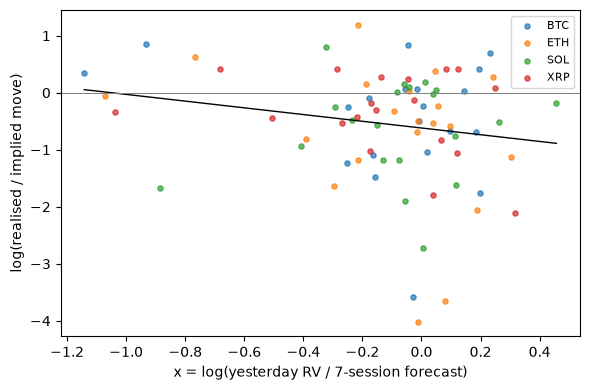

In [4]:
prim = bf.session_boot_slope(D, 'y', P)
prim['verdict'] = bf.rs04_verdict(prim)
print('PRIMARY  slope of log(realised/implied move) on x:', json.dumps(prim, default=float))
print('VERDICT:', prim['verdict'])
dec = pd.DataFrame([{'outcome': c, **bf.session_boot_slope(D, c, P)} for c in ('y', 'y_real', 'y_impl')])
dec['meaning'] = ['realised / implied', 'realised move / sigma_hat', 'implied move / sigma_hat']
display(dec.round(4))
terc = (D.groupby('tercile').agg(n=('R_net', 'size'), sessions=('session', 'nunique'), R_net=('R_net', 'mean'),
                                 move_over_implied=('move_over_implied', 'mean'), x_mean=('x', 'mean'))
          .reindex(['low', 'mid', 'high']))
tb = pd.DataFrame([{'tercile': k, **ls.bootstrap_mean(ls.session_means(D[D.tercile == k], 'R_net').to_numpy(), n_boot=2000)}
                   for k in ('low', 'mid', 'high')]).set_index('tercile')
display(terc.join(tb[['M', 'ci_low', 'ci_high']]).round(4))
fig, ax = plt.subplots(figsize=(6, 4))
for a, g in D.groupby('underlying'):
    ax.scatter(g.x, g.y, s=14, label=a, alpha=0.7)
xx = np.linspace(D.x.min(), D.x.max(), 10)
ax.plot(xx, D.y.mean() + prim['beta'] * (xx - D.x.mean()), 'k-', lw=1)
ax.axhline(0, color='grey', lw=0.7); ax.set_xlabel('x = log(yesterday RV / 7-session forecast)')
ax.set_ylabel('log(realised / implied move)'); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

In [5]:
D[['session', 'underlying', 'x', 'y', 'y_real', 'y_impl', 'R_net', 'move_over_implied', 'tercile', 'settle_source']].to_csv(
    OUT / '04_session_asset.csv', index=False, float_format='%.6g')
dec.to_csv(OUT / '04_slopes.csv', index=False)
terc.join(tb[['M', 'ci_low', 'ci_high']]).to_csv(OUT / '04_terciles.csv')
(OUT / '04_manifest.json').write_text(json.dumps({'registration': bf.registration(P), 'synthetic': SYNTHETIC,
    'primary': prim, 'cutoffs': CUT, 'sessions': [D.session.min(), D.session.max()],
    'run_utc': str(pd.Timestamp.now(tz='UTC'))}, indent=2, default=str), encoding='utf-8')
print('saved', sorted(p.name for p in OUT.iterdir()))

saved ['04_delivery_prices.csv', '04_manifest.json', '04_session_asset.csv', '04_slopes.csv', '04_terciles.csv']
